# Part A (ridge only): polynomial-kernel ridge regression, degree 1-10
- **OFF cases** (nmos_off, pmos_off): the target is `log10|I|` (sign predicted separately by the repo's `SignModel`).
- **ON cases** (nmos_on, pmos_on): the target is the raw signed current `I`, standardised per terminal.
- Model: kernel ridge with a polynomial kernel `(gamma*x.y + 1)^d`, d = 1..10, on the repo's physics features. The ridge penalty is swept per degree; the best (degree, alpha) per case and terminal is chosen on the validation set.
- Reuses the repo's `common/` code for data loading, the 70/15/15 split, features and metrics.

In [1]:
import sys, numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
from pathlib import Path
from scipy.linalg import eigh
from sklearn.preprocessing import StandardScaler
from IPython.display import Image, display
REPO = Path.cwd(); sys.path.insert(0, str(REPO/"ML models"))
from common.config import CASES, SEED, SPLIT, TARGET_COLUMNS
from common.data import load_case, split
from common.features import build_features
from common.metrics import summarise
from common.surrogate import SignModel, log_magnitude
from common.training import parity_plot
DATA = REPO/"Datasets"/"data"; OUT = REPO/"results_ridge"; OUT.mkdir(exist_ok=True)
DEGREES = range(1, 11); ALPHAS = 10.0**np.arange(-8, 1)

## Kernel ridge with a polynomial kernel: one eigendecomposition per degree, then every alpha is cheap

In [2]:
def poly_kernel(A, B, d, gamma):
    return (gamma * A @ B.T + 1.0) ** d

def run_case(case, log_target=None):
    df = load_case(case, DATA); train, val, test = split(df, SPLIT, SEED)
    pol = CASES[case][0]
    if log_target is None: log_target = case.endswith("off")
    tag = f"{case}_{'log' if log_target else 'raw'}"
    fs = StandardScaler().fit(build_features(train, pol))
    X = {k: fs.transform(build_features(s, pol)) for k, s in dict(tr=train, va=val, te=test).items()}
    Y = {k: s[TARGET_COLUMNS].to_numpy() for k, s in dict(tr=train, va=val, te=test).items()}
    signs = np.where(Y["tr"] >= 0, 1.0, -1.0); sm = SignModel().fit(X["tr"], signs)
    T = log_magnitude(Y["tr"]) if log_target else Y["tr"]
    mu, sd = T.mean(0), T.std(0) + 1e-300; Tn = (T - mu) / sd
    gamma = 1.0 / X["tr"].shape[1]
    def to_current(P, Xs):
        P = P * sd + mu
        if log_target: P = np.clip(P, T.min(0) - 1, T.max(0) + 1)  # stop poly extrapolation overflowing 10**P
        return sm.predict(Xs) * np.maximum(10.0 ** P, 1e-18) if log_target else P
    rows, best = [], None
    for d in DEGREES:
        K = poly_kernel(X["tr"], X["tr"], d, gamma); Kv = poly_kernel(X["va"], X["tr"], d, gamma)
        w, V = eigh(K); VtT = V.T @ Tn
        for a in ALPHAS:
            coef = V @ (VtT / (np.maximum(w, 0) + a)[:, None])
            s = summarise(Y["va"], to_current(Kv @ coef, X["va"]))
            rows.append(dict(case=tag, degree=d, alpha=a, r2_log=s["r2_log"], median_error_pct=s["median_error_pct"],
                             p95_error_pct=s["p95_error_pct"], id_median=s["id_median_error_pct"], id_p95=s["id_p95_error_pct"]))
            if best is None or (s["p95_error_pct"], s["median_error_pct"]) < best[0]:
                best = ((s["p95_error_pct"], s["median_error_pct"]), d, a, coef)
        print(f"{case} degree {d} done", flush=True)
    _, d, a, coef = best
    pred = to_current(poly_kernel(X["te"], X["tr"], d, gamma) @ coef, X["te"])
    ts = summarise(Y["te"], pred)
    parity_plot(Y["te"], pred, case, f"kernel ridge d={d}, alpha={a:g}", OUT/f"parity_{tag}.png")
    joblib.dump(dict(case=case, degree=d, alpha=a, gamma=gamma, coef=coef, Xtrain=X["tr"], feature_scaler=fs,
                     target_mu=mu, target_sd=sd, log_target=log_target, sign_model=sm), OUT/f"{tag}.joblib", compress=3)
    return pd.DataFrame(rows), dict(case=tag, target="log10|I|" if log_target else "I", degree=d, alpha=a,
                                    **{k: ts[k] for k in ["r2_log","median_error_pct","p95_error_pct","id_median_error_pct","id_p95_error_pct"]})

## nmos_on (raw target)

In [3]:
sweep_nmos_on_raw, test_nmos_on_raw = run_case("nmos_on", False)
sweep_nmos_on_raw.to_csv(OUT/"sweep_nmos_on_raw.csv", index=False)

C:\Users\anees\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\anees\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\anees\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\anees\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\anees\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

nmos_on degree 1 done


nmos_on degree 2 done


nmos_on degree 3 done


nmos_on degree 4 done


nmos_on degree 5 done


nmos_on degree 6 done


nmos_on degree 7 done


nmos_on degree 8 done


nmos_on degree 9 done


nmos_on degree 10 done


## nmos_on (log target)

In [4]:
sweep_nmos_on_log, test_nmos_on_log = run_case("nmos_on", True)
sweep_nmos_on_log.to_csv(OUT/"sweep_nmos_on_log.csv", index=False)

nmos_on degree 1 done


nmos_on degree 2 done


nmos_on degree 3 done


nmos_on degree 4 done


nmos_on degree 5 done


nmos_on degree 6 done


nmos_on degree 7 done


nmos_on degree 8 done


nmos_on degree 9 done


nmos_on degree 10 done


## nmos_off (log target)

In [5]:
sweep_nmos_off_log, test_nmos_off_log = run_case("nmos_off", True)
sweep_nmos_off_log.to_csv(OUT/"sweep_nmos_off_log.csv", index=False)

nmos_off degree 1 done


nmos_off degree 2 done


nmos_off degree 3 done


nmos_off degree 4 done


nmos_off degree 5 done


nmos_off degree 6 done


nmos_off degree 7 done


nmos_off degree 8 done


nmos_off degree 9 done


nmos_off degree 10 done


## pmos_on (raw target)

In [6]:
sweep_pmos_on_raw, test_pmos_on_raw = run_case("pmos_on", False)
sweep_pmos_on_raw.to_csv(OUT/"sweep_pmos_on_raw.csv", index=False)

pmos_on degree 1 done


pmos_on degree 2 done


pmos_on degree 3 done


pmos_on degree 4 done


pmos_on degree 5 done


pmos_on degree 6 done


pmos_on degree 7 done


pmos_on degree 8 done


pmos_on degree 9 done


pmos_on degree 10 done


## pmos_on (log target)

In [7]:
sweep_pmos_on_log, test_pmos_on_log = run_case("pmos_on", True)
sweep_pmos_on_log.to_csv(OUT/"sweep_pmos_on_log.csv", index=False)

pmos_on degree 1 done


pmos_on degree 2 done


pmos_on degree 3 done


pmos_on degree 4 done


pmos_on degree 5 done


pmos_on degree 6 done


pmos_on degree 7 done


pmos_on degree 8 done


pmos_on degree 9 done


pmos_on degree 10 done


## pmos_off (log target)

In [8]:
sweep_pmos_off_log, test_pmos_off_log = run_case("pmos_off", True)
sweep_pmos_off_log.to_csv(OUT/"sweep_pmos_off_log.csv", index=False)

pmos_off degree 1 done


pmos_off degree 2 done


pmos_off degree 3 done


pmos_off degree 4 done


pmos_off degree 5 done


pmos_off degree 6 done


pmos_off degree 7 done


pmos_off degree 8 done


pmos_off degree 9 done


pmos_off degree 10 done


## Validation sweep: best alpha per degree

In [9]:
VAR = ["nmos_on_raw","nmos_on_log","nmos_off_log","pmos_on_raw","pmos_on_log","pmos_off_log"]
for k in VAR:
    s = globals()[f"sweep_{k}"]; print(k)
    display(s.loc[s.groupby("degree")["p95_error_pct"].idxmin()].set_index("degree").drop(columns="case"))

nmos_on_raw


,alpha,r2_log,median_error_pct,p95_error_pct,id_median,id_p95
degree,,,,,,
1,0.100,-0.415564,294.567739,398796.256440,73.150387,2.570726e+06
2,0.001,-0.239016,142.848981,246210.743049,33.427375,8.163092e+05
3,0.100,-0.074237,79.836417,187756.542468,13.073302,6.521423e+05
4,1.000,0.094309,50.679221,114338.593399,6.676823,3.353672e+05
5,1.000,0.269401,30.697360,69351.356955,4.464760,2.330759e+05
6,1.000,0.353074,22.213674,45387.716149,3.887640,2.328071e+05
7,1.000,0.404737,16.752602,38169.363593,3.562170,3.015914e+05
8,1.000,0.440727,14.249184,34608.069481,3.803032,3.437836e+05
9,1.000,0.478599,13.098194,28055.120641,4.155281,2.825522e+05


nmos_on_log


,alpha,r2_log,median_error_pct,p95_error_pct,id_median,id_p95
degree,,,,,,
1,0.00001,0.890169,58.127950,652.332584,77.972067,1391.469994
2,0.00010,0.993313,15.742640,61.294595,22.723784,73.310872
3,0.00100,0.994036,10.669135,38.365703,13.204475,46.211021
4,0.10000,0.996012,6.294660,24.744059,6.877779,24.249323
5,1.00000,0.987200,4.733330,20.807899,4.675028,17.401724
6,1.00000,0.991480,4.068958,19.753100,3.759286,15.185088
7,1.00000,0.985208,3.893791,21.412739,3.402574,16.145285
8,1.00000,0.980822,4.041929,24.981390,3.707355,19.055473
9,1.00000,0.969435,4.433940,30.596974,4.070210,25.743630


nmos_off_log


,alpha,r2_log,median_error_pct,p95_error_pct,id_median,id_p95
degree,,,,,,
1,1.000000,0.682847,43.622282,608.405361,82.180927,1242.508286
2,0.000001,0.891413,19.099213,221.771729,53.074178,444.610587
3,1.000000,0.951393,16.479431,90.569852,34.003031,165.849022
4,1.000000,0.953779,11.827081,69.472873,22.918347,132.575744
5,1.000000,0.946173,11.217694,68.248388,22.536504,116.226962
6,1.000000,0.913150,10.341128,73.453931,21.005689,138.992388
7,1.000000,0.884874,10.196133,86.811138,21.677640,161.866109
8,1.000000,0.848731,10.974221,111.357453,24.934967,230.008542
9,1.000000,0.814554,11.988041,149.812840,28.020845,336.080010


... (2 outputs left out)

pmos_on_log


,alpha,r2_log,median_error_pct,p95_error_pct,id_median,id_p95
degree,,,,,,
1,0.010,0.877338,71.157880,602.134494,80.033427,1629.404622
2,0.001,0.991429,22.747376,71.640689,24.356842,69.621091
3,0.010,0.994847,11.263912,40.213113,12.302386,42.543728
4,0.100,0.991755,7.142409,25.621599,7.014540,24.382234
5,1.000,0.993367,4.625718,19.028033,4.455030,16.675623
6,1.000,0.985537,3.871273,18.246723,3.438586,15.039808
7,1.000,0.987111,3.727483,18.858707,3.296433,15.064941
8,1.000,0.981867,3.755528,22.173663,3.434459,18.416365
9,1.000,0.964605,4.241626,28.634406,3.841779,22.835471


pmos_off_log


,alpha,r2_log,median_error_pct,p95_error_pct,id_median,id_p95
degree,,,,,,
1,1.000000e-01,0.734420,72.631330,3544.527850,96.064450,3129.738533
2,1.000000e-08,0.866842,32.501048,772.720273,48.922550,487.525603
3,1.000000e-02,0.870748,30.098977,409.583309,36.359414,205.054847
4,1.000000e+00,0.872355,26.611694,397.823993,30.049043,159.273923
5,1.000000e+00,0.856625,23.918639,399.291845,26.483321,127.980368
6,1.000000e+00,0.814903,25.094865,474.413500,26.828325,193.624805
7,1.000000e+00,0.737778,27.516125,637.497817,29.572535,264.921699
8,1.000000e+00,0.654700,31.695108,853.087449,32.454110,370.325240
9,1.000000e+00,0.575358,35.862673,1309.818993,37.650793,626.899754


## Chosen (degree, alpha) and test-set results

,case,target,degree,alpha,r2_log,median_error_pct,p95_error_pct,id_median_error_pct,id_p95_error_pct
0,nmos_on_raw,I,10,1.0,0.500152,12.352814,32252.865685,5.508402,419810.177209
1,nmos_on_log,log10|I|,6,1.0,0.997270,3.959415,20.556046,3.538076,17.140068
2,nmos_off_log,log10|I|,5,1.0,0.947617,11.558973,74.974693,22.590192,157.339051
3,pmos_on_raw,I,10,1.0,0.396075,19.314707,80689.028823,4.135462,877342.349461
4,pmos_on_log,log10|I|,6,1.0,0.998604,4.267531,18.609489,3.679260,15.139955
5,pmos_off_log,log10|I|,4,1.0,0.866966,27.108382,352.148070,31.590621,201.057551


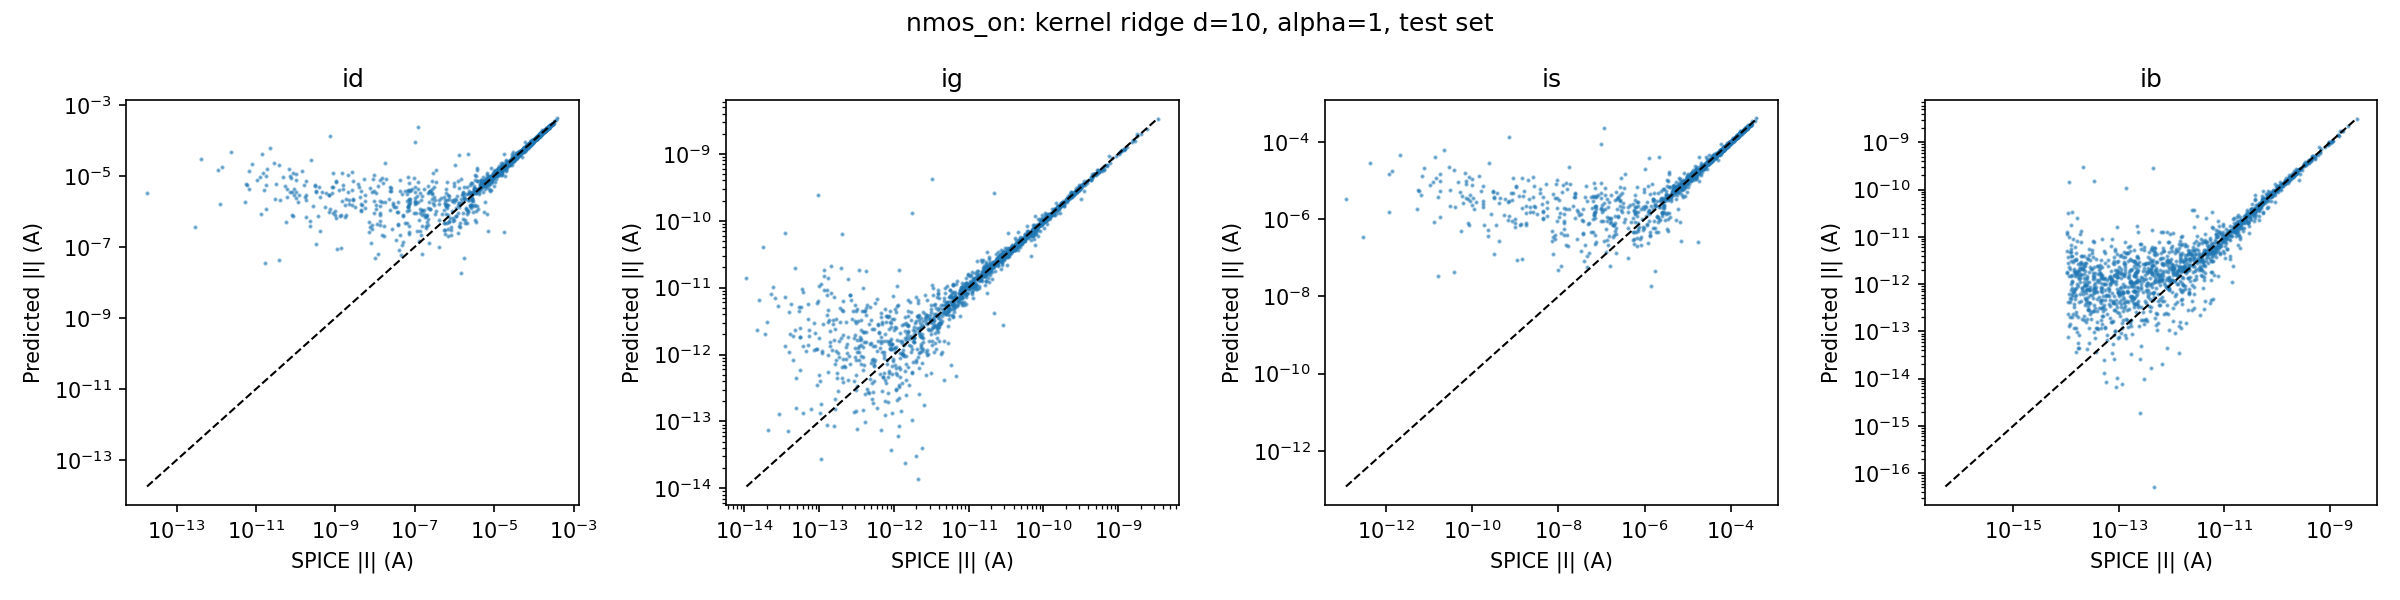

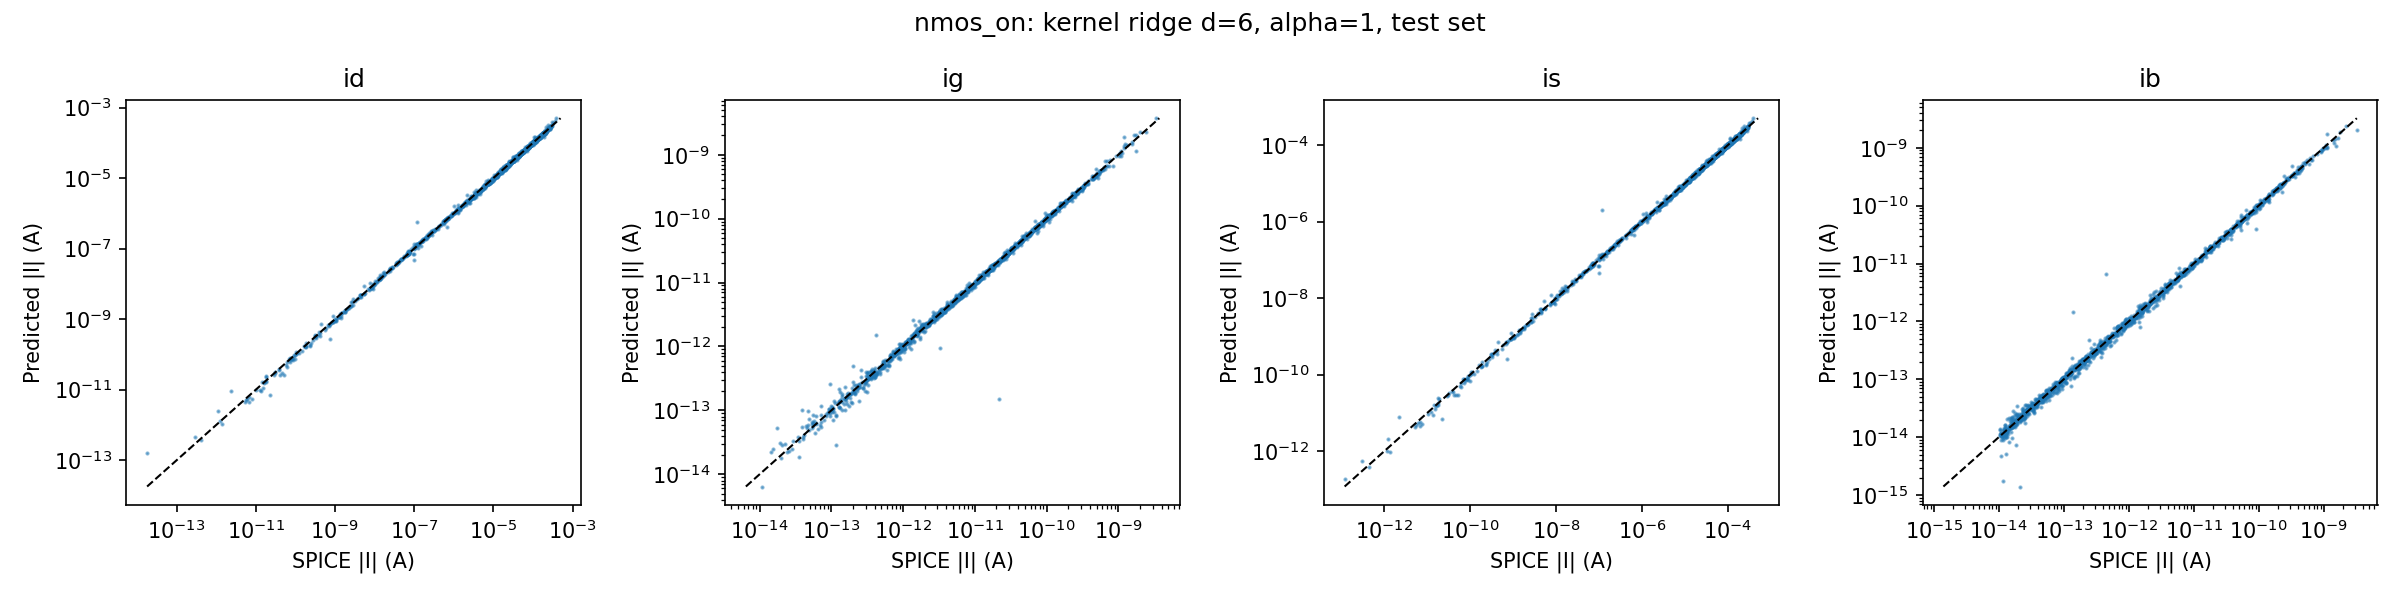

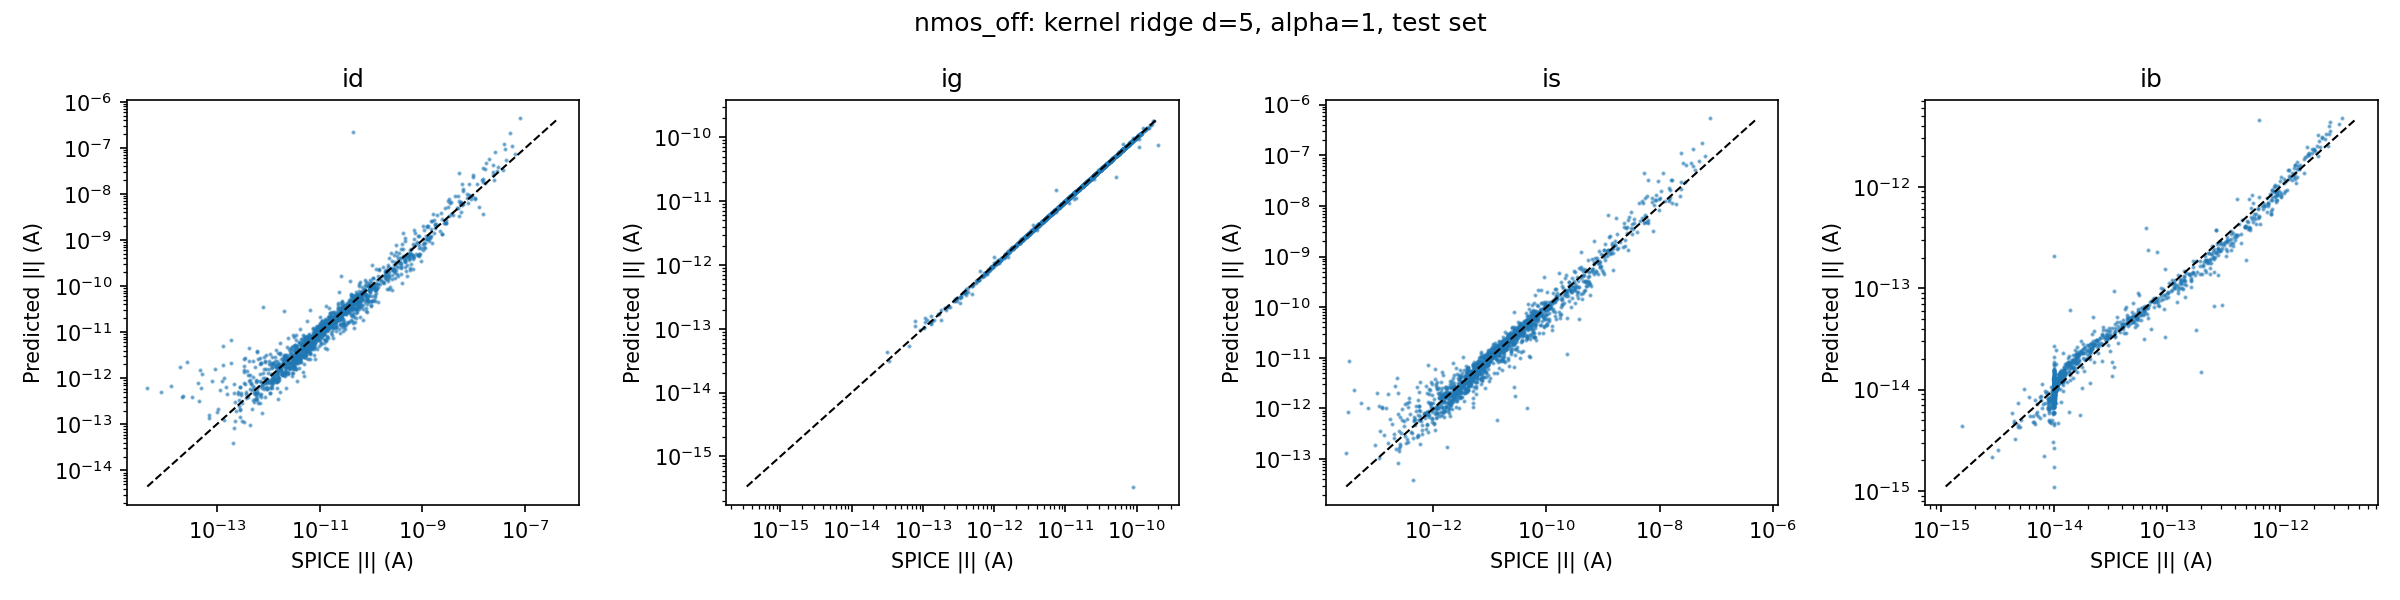

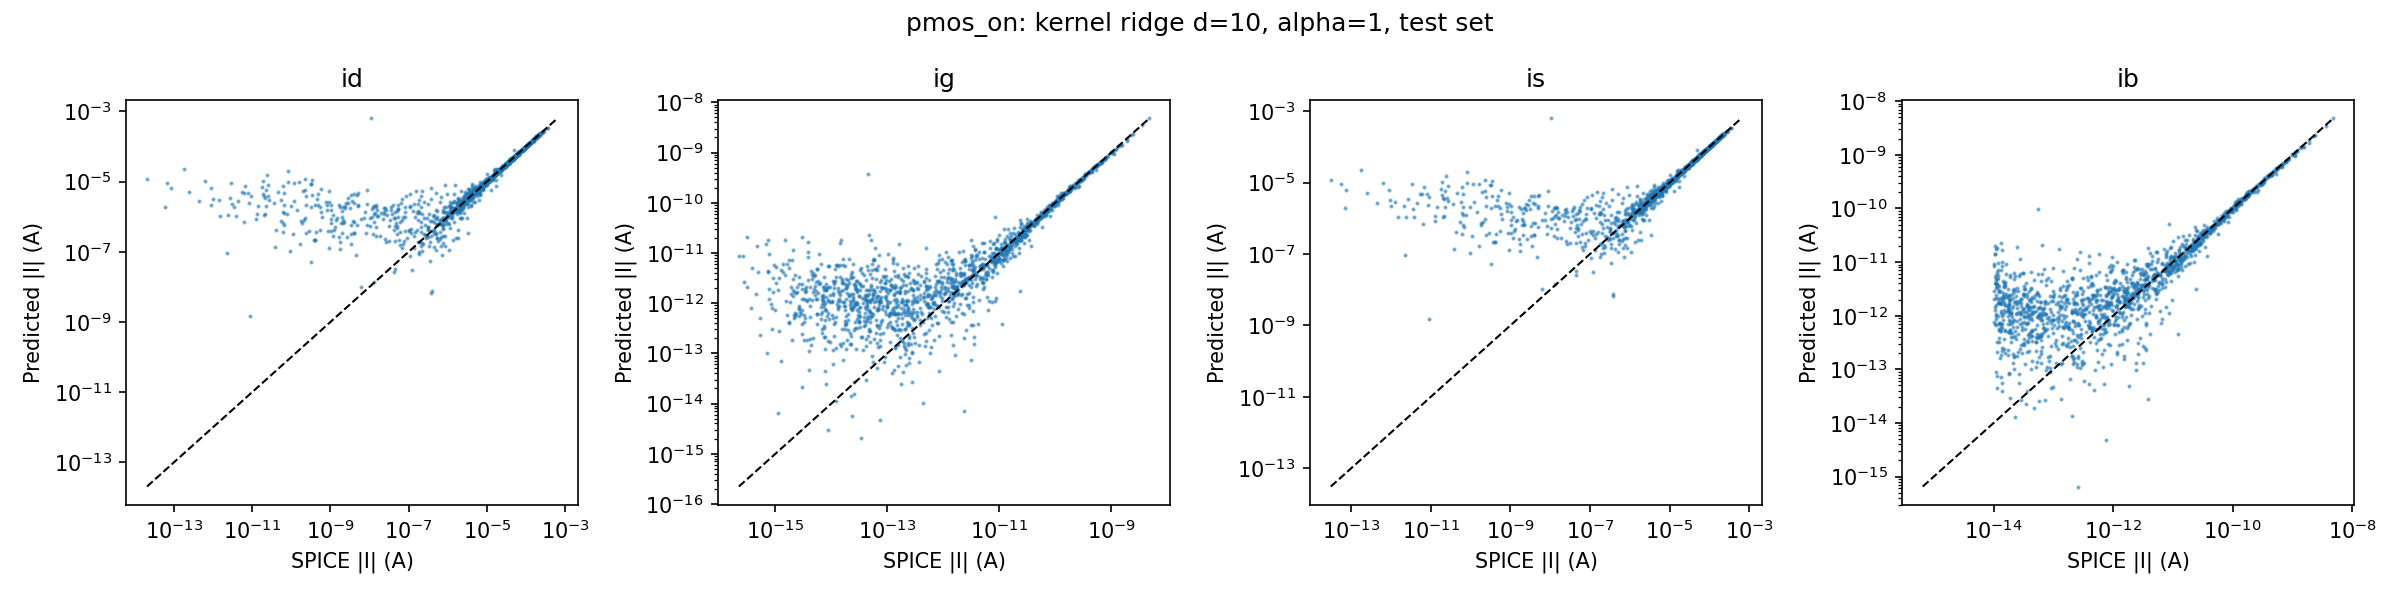

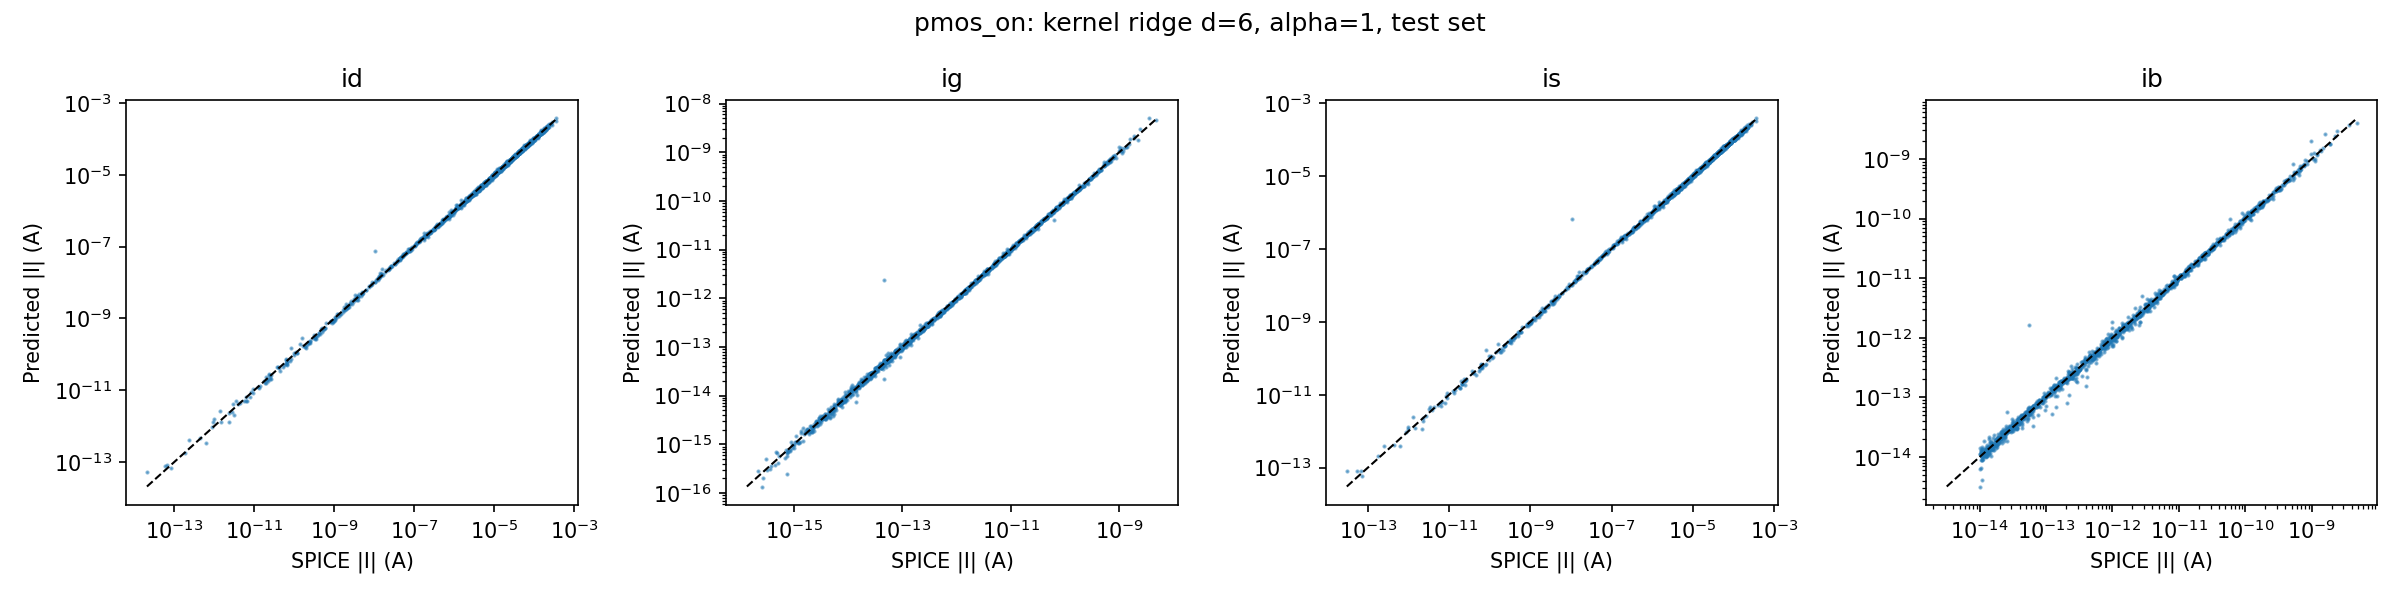

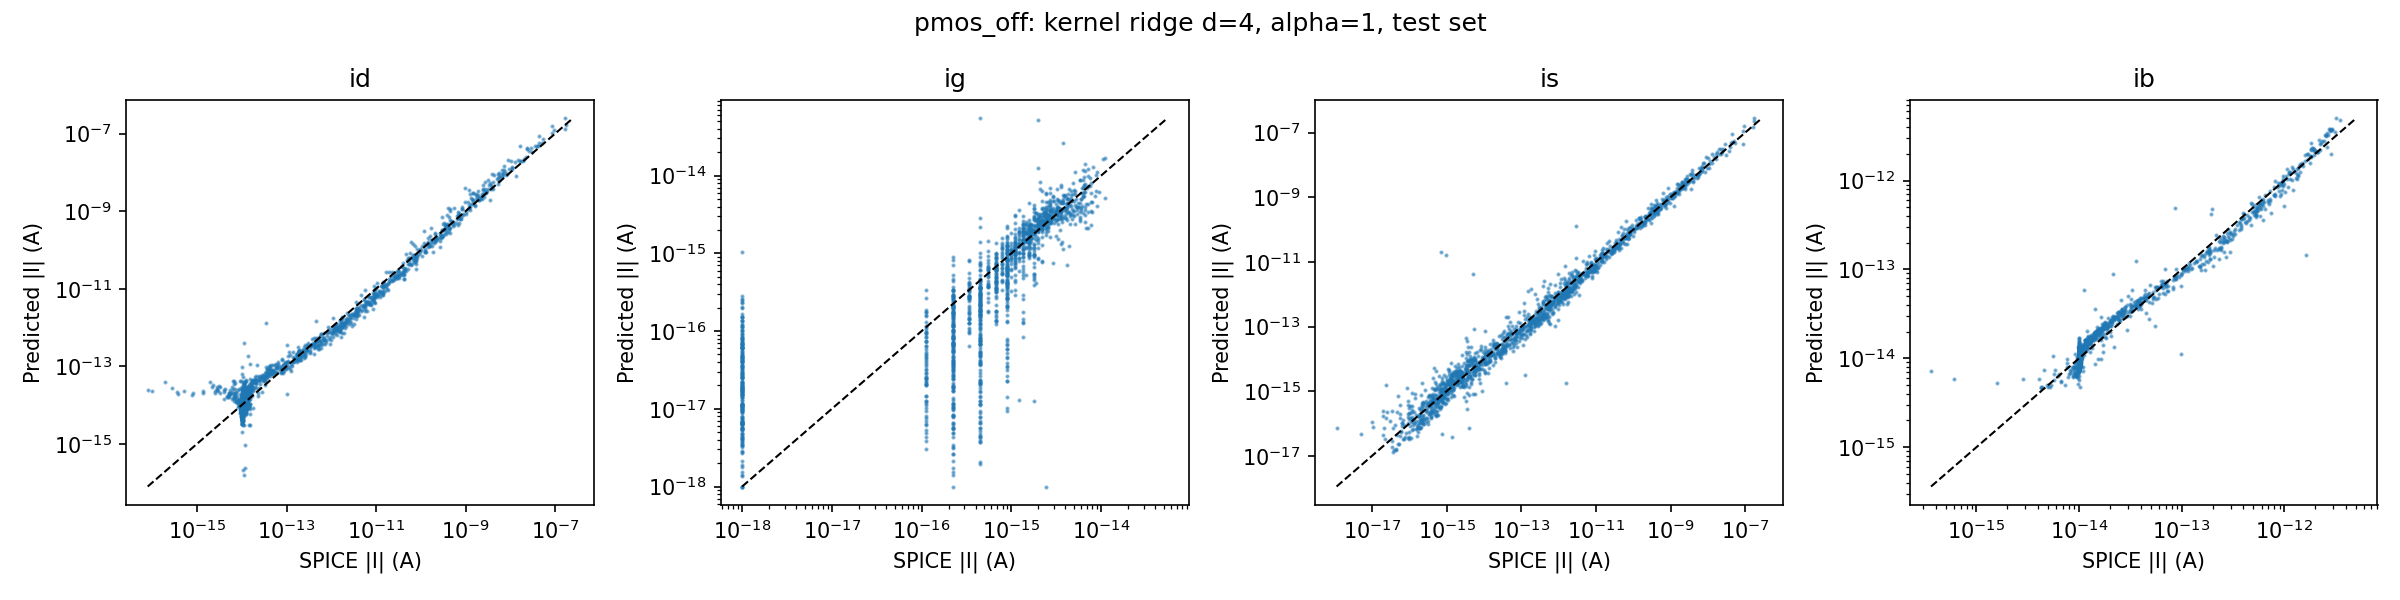

In [10]:
res = pd.DataFrame([globals()[f"test_{k}"] for k in VAR]); res.to_csv(OUT/"test_metrics.csv", index=False); display(res)
for k in VAR: display(Image(OUT/f"parity_{k}.png"))